# 16.4 - Frontal alignment pilot preparation

Verify the 36 source-image candidates, preserve source split and inspect actual photographs. The original OMNI annotations use a broader tooth misalignment category. Target boxes and target-negative status require separate annotation.

## Verify provenance and split

Image bytes are validated against the OMNI archive audit manifest. No test images are opened.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
root=Path.cwd()
while not (root/'pyproject.toml').exists():
    if root == root.parent: raise RuntimeError('Project root unavailable')
    root=root.parent
pilot=root/'data/processed/alignment_omni_pilot'
frame=pd.read_csv(pilot/'pilot_provenance.csv',dtype={'source_image_id':str})
assert len(frame)==36 and frame.source_image_id.is_unique
for row in frame.itertuples():
    path=pilot/'images'/row.split/(row.source_image_id+'.jpg')
    assert hashlib.sha256(path.read_bytes()).hexdigest()==row.sha256
display(frame.groupby('split').agg(images=('source_image_id','size'),source_tm_boxes=('tm_boxes','sum')))

,images,source_tm_boxes
split,,
train,26,34
val,10,13


## Inspect representative photos

Filename suffix selects candidates for review. Source TM is a broad condition and does not define the two target boxes.

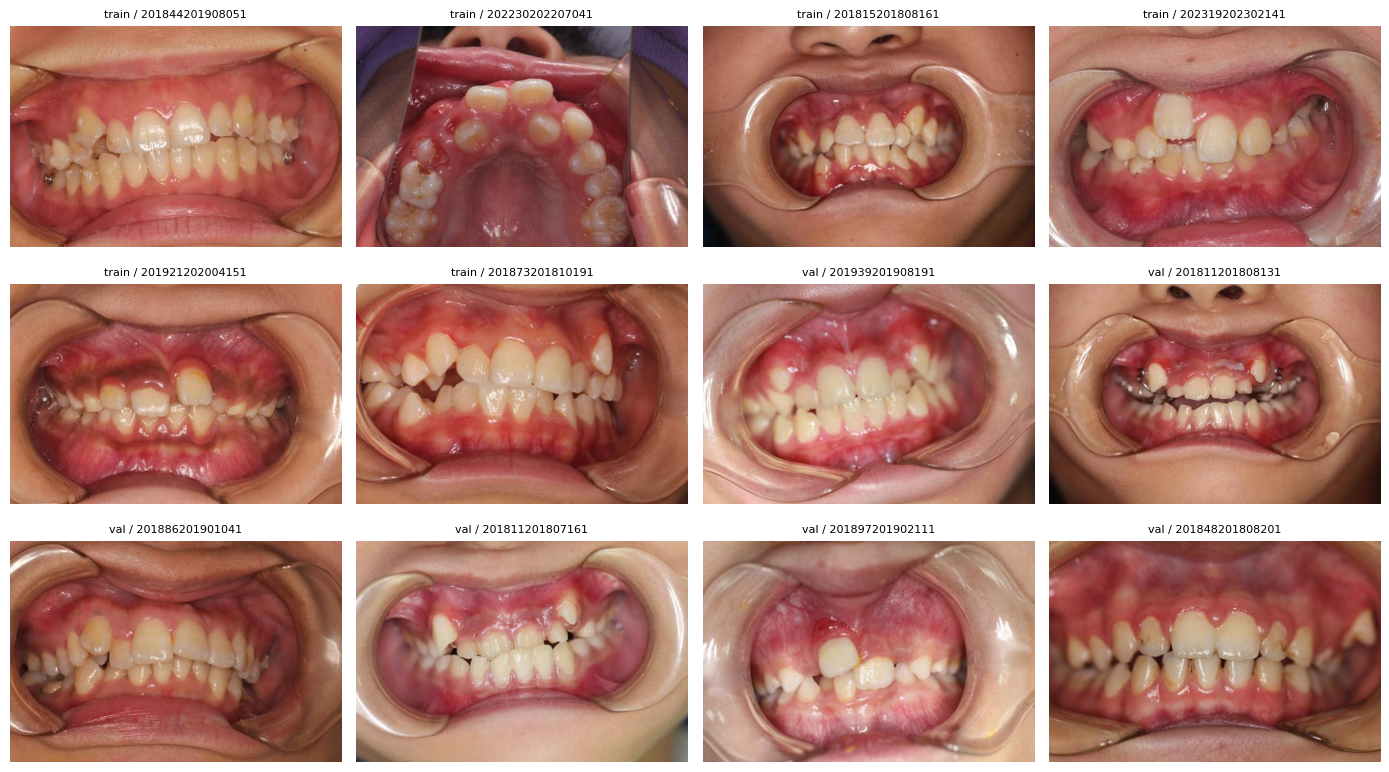

In [2]:
fig,axes=plt.subplots(3,4,figsize=(14,8))
sample=pd.concat([frame[frame.split==split].sample(6,random_state=42) for split in ['train','val']])
for ax,row in zip(axes.flat,sample.itertuples()):
    with Image.open(pilot/'images'/row.split/(row.source_image_id+'.jpg')) as image:
        ax.imshow(image)
    ax.set_title(row.split+' / '+row.source_image_id,fontsize=8);ax.axis('off')
plt.tight_layout();plt.show()

## Review status and class definitions

Both targets must be assessed separately. Present cases need a box, absent cases need a reviewed visible region, and unclear cases remain uncertain. No target annotations are invented by this notebook.

In [3]:
for column in ['view_review','dentition_review','diastema_review','crowding_review']:
    print(column,frame[column].value_counts(dropna=False).to_dict())
print('Targets: upper midline diastema; anterior crowding')
print('All target statuses remain pending in the supplied pilot.')

view_review {'pending': 36}
dentition_review {'pending': 36}
diastema_review {'pending': 36}
crowding_review {'pending': 36}
Targets: upper midline diastema; anterior crowding
All target statuses remain pending in the supplied pilot.
